# 02 · Dataset, EDA and data-quality assessment
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**What this notebook does**
1. **Data dictionary**: source tables (grain, key, size) and every column the project uses, with its role.
2. **Analysis populations** for the three outcomes: DL pass rush, OL pass blocking, OL run blocking.
3. **Descriptive statistics**: Combine measurables by group, outcome rates, snaps per player.
4. **Data-quality assessment**: missing stopwatch results, drill-name inconsistency, the unreliable `dis` column, unsigned acceleration, row count vs documentation, season labelling, run-gap coverage, missing lineman side.
5. **Visualizations** saved to `outputs/figures/02_*.png`.
6. **Whole-release view** (team EDA by Isaac Marr): size of the full data set by season and season type, Combine drill coverage for every position, the lineman drills, how many players have enough snaps, DL get-off by alignment, and a first look at the 10-yard split against get-off.

Sections 1–5 use notebook 01 outputs; section 6 reads the raw CSVs. **Outputs:** `outputs/tables/02_*.csv`, `outputs/figures/02_*.png`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
import config as C

spark = C.get_spark("02_eda")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_colwidth", 110, "display.width", 200)
BLUE, ORANGE, GREY = "#2a6fdb", "#e07b39", "#8a8a8a"
players = spark.read.parquet(C.p("line_players.parquet"))
plays = spark.read.parquet(C.p("line_player_play.parquet"))
ct = spark.read.parquet(C.p("combine_tracking.parquet"))
gt = spark.read.parquet(C.p("line_game_tracking.parquet"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/26 21:23:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Data dictionary
### 1a. Source tables

In [2]:
tables = pd.DataFrame([
    ("players.csv", "player", "nfl_id", "Demographics, draft round / pick"),
    ("combine_results.csv", "player", "nfl_id", "Measurables and stopwatch drills"),
    ("combine_tracking.csv", "10 Hz frame of a drill attempt", "event_id + time", "Combine optical tracking (x, y, speed, accel., direction)"),
    ("player_play.csv", "player × play", "game_id + play_id + nfl_id", "Play context, play-by-play text, NGS pass-rush / pass-block metrics"),
    ("games.csv", "game", "game_id", "Season, week, season type"),
    ("game_tracking_2023–25.csv", "10 Hz frame of an NFL play", "game_id + play_id + nfl_id + time", "In-game tracking of the 510 rookies (~2 GB)"),
    ("player_career_successes.csv", "player", "nfl_id", "Career snaps and starts"),
], columns=["file", "grain (one row =)", "key", "content"])
tables["rows used (OL + DL cohort)"] = ["239", "239", f"{ct.count():,}", f"{plays.count():,}", "1,002", f"{gt.count():,}", "239"]
tables.to_csv(C.TABLE_DIR / "02_source_tables.csv", index=False)
tables

,file,grain (one row =),key,content,rows used (OL + DL cohort)
0,players.csv,player,nfl_id,"Demographics, draft round / pick",239
1,combine_results.csv,player,nfl_id,Measurables and stopwatch drills,239
2,combine_tracking.csv,10 Hz frame of a drill attempt,event_id + time,"Combine optical tracking (x, y, speed, accel., direction)","176,224"
3,player_play.csv,player × play,game_id + play_id + nfl_id,"Play context, play-by-play text, NGS pass-rush / pass-block metrics","175,955"
4,games.csv,game,game_id,"Season, week, season type","1,002"
5,game_tracking_2023–25.csv,10 Hz frame of an NFL play,game_id + play_id + nfl_id + time,In-game tracking of the 510 rookies (~2 GB),"12,422,030"
6,player_career_successes.csv,player,nfl_id,Career snaps and starts,239


### 1b. Columns used in modeling
Roles: **target**, **context** (known before the snap), **trait** (from Combine tracking, notebook 03), **stopwatch**, **size**, **id/split**, **attribution** (notebook 04), **excluded** (post-snap, would leak the outcome).

In [3]:
dd = [
 ("pressure (DL)", "target", "player_play", "1 if the rusher has a time-to-pressure, a QB hurry, or a sack"),
 ("player_get_off (DL)", "target", "player_play", "Seconds from snap until the rusher crosses the line"),
 ("pressure_allowed (OL)", "target", "player_play", "True if the lineman allowed a hurry, hit or sack"),
 ("peak_pressure_probability_allowed (OL)", "target", "player_play", "Peak NGS pressure probability he allowed (0–1)"),
 ("run_success (OL)", "target", "derived", "EPA > 0 on a run where he is at the point of attack"),
 ("down, yards_to_go, dist_bucket, quarter, half_seconds_left, is_two_minute", "context", "player_play", "Game situation"),
 ("yards_from_own_goal, team_score_diff, team_win_prob, is_home", "context", "derived", "Field position, score and win probability from his team's side"),
 ("offense_formation, receiver_alignment, lined_up_position", "context", "player_play", "Rare levels (< 1%) grouped as OTHER"),
 ("nfl_experience", "context", "derived", "season − draft year"),
 ("run_gap, slot, credit (OL run)", "attribution", "nb 04", "Gap from play-by-play text; lineman slot LT…RT; credit 1 / 0.5"),
 ("trk_first_step, trk_lateral, trk_burst", "trait", "nb 03", "Tracking trait indices (z-scores within group, higher = better)"),
 ("adj_first_step, adj_lateral, adj_burst", "trait", "nb 03", "Same, after removing the effect of body weight"),
 ("sw_first_step, sw_lateral, sw_burst (+ miss flags)", "stopwatch", "nb 03", "10-yd split; shuttle + 3-cone; broad + vertical + 40"),
 ("combine_weight, combine_height, arm_length", "size", "combine_results", "Measurables"),
 ("nfl_id, draft_year, split, fold", "id/split", "players / nb 05", "Player-grouped splits; 2025 class = test"),
 ("pass_result, dropback_duration, time_to_pressure_allowed, pass_rushers_encountered, sack", "excluded", "player_play", "Post-snap: define or follow the outcome"),
]
data_dict = pd.DataFrame(dd, columns=["column(s)", "role", "source", "description"])
data_dict.to_csv(C.TABLE_DIR / "02_data_dictionary.csv", index=False)
data_dict

,column(s),role,source,description
0,pressure (DL),target,player_play,"1 if the rusher has a time-to-pressure, a QB hurry, or a sack"
1,player_get_off (DL),target,player_play,Seconds from snap until the rusher crosses the line
2,pressure_allowed (OL),target,player_play,"True if the lineman allowed a hurry, hit or sack"
3,peak_pressure_probability_allowed (OL),target,player_play,Peak NGS pressure probability he allowed (0–1)
4,run_success (OL),target,derived,EPA > 0 on a run where he is at the point of attack
5,"down, yards_to_go, dist_bucket, quarter, half_seconds_left, is_two_minute",context,player_play,Game situation
6,"yards_from_own_goal, team_score_diff, team_win_prob, is_home",context,derived,"Field position, score and win probability from his team's side"
7,"offense_formation, receiver_alignment, lined_up_position",context,player_play,Rare levels (< 1%) grouped as OTHER
8,nfl_experience,context,derived,season − draft year
9,"run_gap, slot, credit (OL run)",attribution,nb 04,Gap from play-by-play text; lineman slot LT…RT; credit 1 / 0.5


## 2. Analysis populations

In [4]:
reg = plays.filter(F.col("season_type") == "REG")
GAP_RE = r"(left end|left tackle|left guard|up the middle|right guard|right tackle|right end)"
reg = reg.withColumn("run_gap", F.regexp_extract(F.lower("play_description"), GAP_RE, 1))
not_null = F.coalesce(F.col("play_nullified_by_penalty"), F.lit("N")) != "Y"
pop = []
dl = reg.filter(F.col("line_group") == "DL")
pop += [("DL", "all regular-season rows", dl.count()),
        ("DL", "pass-rush snaps (dropback + get-off, not nullified)",
         dl.filter(F.col("player_get_off").isNotNull() & F.col("pass_result").isin("C", "I", "IN", "S", "R") & not_null).count())]
ol = reg.filter((F.col("line_group") == "OL") & F.col("lined_up_position").isin("T", "G", "C"))
pop += [("OL", "all regular-season rows at T/G/C", ol.count()),
        ("OL", "pass-block snaps (pressure_allowed recorded)", ol.filter(F.col("pressure_allowed").isNotNull() & not_null).count()),
        ("OL", "run snaps (no pass result)", ol.filter(F.col("pass_result").isNull()).count()),
        ("OL", "run snaps with a run gap in the text", ol.filter(F.col("pass_result").isNull() & (F.col("run_gap") != "")).count())]
pop = pd.DataFrame(pop, columns=["group", "population", "rows"]); pop.to_csv(C.TABLE_DIR / "02_populations.csv", index=False)
pop

,group,population,rows
0,DL,all regular-season rows,52609
1,DL,"pass-rush snaps (dropback + get-off, not nullified)",25283
2,OL,all regular-season rows at T/G/C,85753
3,OL,pass-block snaps (pressure_allowed recorded),48536
4,OL,run snaps (no pass result),33994
5,OL,run snaps with a run gap in the text,32672


## 3. Descriptive statistics
### 3a. Combine measurables and stopwatch drills by group

In [5]:
meas = ["combine_height", "combine_weight", "arm_length", "forty", "ten_yd_split", "vertical", "broad_jump",
        "three_cone", "short_shuttle", "bench_reps", "age_at_draft"]
desc = (C.describe(players, meas, by=["line_group"]).withColumnRenamed("line_group", "group")   # computed in Spark
          .toPandas().round(2))
desc["column"] = pd.Categorical(desc.column, meas); desc = desc.sort_values(["group", "column"]).reset_index(drop=True)
desc.to_csv(C.TABLE_DIR / "02_combine_descriptives.csv", index=False)
miss = desc.set_index(["group", "column"]).missing_pct          # % of prospects without the measurement
desc

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,group,column,count,mean,std,min,median,max,missing_pct
0,DL,combine_height,118,75.54,1.41,72.25,75.62,79.38,0.00
1,DL,combine_weight,118,281.59,29.41,236.00,279.00,366.00,0.00
2,DL,arm_length,118,33.24,1.03,31.00,33.25,36.88,0.00
3,DL,forty,94,4.86,0.25,4.43,4.80,5.41,20.34
4,DL,ten_yd_split,94,1.70,0.08,1.54,1.67,1.88,20.34
5,DL,vertical,102,32.09,3.63,23.00,32.00,40.50,13.56
6,DL,broad_jump,97,114.94,8.54,93.00,116.00,132.00,17.80
7,DL,three_cone,43,7.42,0.29,6.94,7.36,8.19,63.56
8,DL,short_shuttle,46,4.58,0.22,4.18,4.58,5.03,61.02
9,DL,bench_reps,54,24.22,3.67,17.00,24.00,32.00,54.24


### 3b. Outcomes

In [6]:
pr = (dl.filter(F.col("player_get_off").isNotNull() & F.col("pass_result").isin("C", "I", "IN", "S", "R") & not_null)
        .withColumn("pressure", ((F.col("time_to_pressure").isNotNull()) | F.col("time_to_qb_hurry").isNotNull() |
                                 (F.coalesce(F.col("sack"), F.lit(0)) > 0)).cast("int")))
pb = ol.filter(F.col("pressure_allowed").isNotNull() & not_null).withColumn("pa", F.col("pressure_allowed").cast("int"))
rn = ol.filter(F.col("pass_result").isNull() & (F.col("run_gap") != "") & not_null).withColumn("success", (F.col("expected_points_added") > 0).cast("int"))
outc = pd.DataFrame([
    ("DL pressure rate", pr.agg(F.avg("pressure")).first()[0], pr.select("nfl_id").distinct().count()),
    ("DL mean get-off (s)", pr.agg(F.avg("player_get_off")).first()[0], None),
    ("OL pressure-allowed rate", pb.agg(F.avg("pa")).first()[0], pb.select("nfl_id").distinct().count()),
    ("OL mean peak pressure probability", pb.agg(F.avg("peak_pressure_probability_allowed")).first()[0], None),
    ("OL run success rate (EPA > 0)", rn.agg(F.avg("success")).first()[0], rn.select("nfl_id").distinct().count()),
], columns=["outcome", "value", "players"])
outc["value"] = outc.value.round(4); outc.to_csv(C.TABLE_DIR / "02_outcomes.csv", index=False)
outc

,outcome,value,players
0,DL pressure rate,0.1052,98.0
1,DL mean get-off (s),0.9617,NaN
2,OL pressure-allowed rate,0.0842,88.0
3,OL mean peak pressure probability,0.2837,NaN
4,OL run success rate (EPA > 0),0.3962,88.0


## 4. Data-quality assessment

In [7]:
dq = []
for g in C.GROUPS:
    for c in ["three_cone", "short_shuttle", "ten_yd_split", "forty", "broad_jump", "vertical"]:
        dq.append(("missing value", f"{g} · {c}", f"{miss[(g, c)]}% of prospects", "trait index from other components; stopwatch index + missing flag"))
names = ct.filter(F.col("drill_name").contains("MIRROR")).select("drill_name").distinct().count()
dq.append(("inconsistent label", "combine_tracking.drill_name", "PASS_PRO-MIRROR_DRILL (2024–25) vs PASS_PRO_MIRROR_DRILL (2023)", f"standardized in nb 01 ({names} name left)"))
dis = ct.filter(F.col("step_xy") > 0.05).select(F.expr("percentile_approx(dis / (step_xy * step_xy), 0.5)").alias("r"),
                                                 F.corr("dis", F.col("step_xy") * F.col("step_xy")).alias("c")).first()
dq.append(("unreliable column", "combine_tracking.dis", f"dis ≈ (x/y step)²: median ratio {dis.r:.2f}, corr {dis.c:.3f}", "distance recomputed from x, y"))
dq.append(("semantics", "combine_tracking.a", f"min = {ct.agg(F.min('a')).first()[0]:.2f}: unsigned magnitude", "signed acceleration from Δspeed (nb 03)"))
dq.append(("row count", "player_play.csv", "314,197 rows vs 316,338 on the competition page", "used as delivered"))
jan = plays.filter((F.substring(F.col("game_id").cast("string"), 5, 2) == "01") &
                   (F.substring(F.col("game_id").cast("string"), 1, 4).cast("int") != F.col("season"))).count()
dq.append(("mislabel risk", "game_id", f"{jan:,} January cohort rows with year ≠ season", "season from games.csv"))
dq.append(("scope", "season_type", f"{plays.filter(F.col('season_type') == 'PRE').count():,} preseason cohort rows", "excluded"))
no_gap = ol.filter(F.col("pass_result").isNull() & (F.col("run_gap") == "")).count()
dq.append(("missing value", "play_description run gap", f"{no_gap:,} OL non-pass rows without a gap (kneels, aborted snaps, penalties)", "excluded from run blocking"))
dq.append(("missing field", "lineman side", "data gives T/G/C only; no left/right", "inferred from position at the snap vs hash marks (nb 04)"))
dq.append(("coverage", "in-game tracking", "only the 510 rookies are tracked: no ball carrier, no blockers or rushers they face", "outcomes from NGS fields + play-by-play text"))
dq.append(("constant column", "player_play.unblocked_pressure", f"non-null on {ol.filter(F.col('unblocked_pressure').isNotNull()).count()} OL rows", "not used"))
dq = pd.DataFrame(dq, columns=["issue", "where", "finding", "treatment"]); dq.to_csv(C.TABLE_DIR / "02_data_quality.csv", index=False)
dq

,issue,where,finding,treatment
0,missing value,OL · three_cone,49.59% of prospects,trait index from other components; stopwatch index + missing flag
1,missing value,OL · short_shuttle,47.11% of prospects,trait index from other components; stopwatch index + missing flag
2,missing value,OL · ten_yd_split,20.66% of prospects,trait index from other components; stopwatch index + missing flag
3,missing value,OL · forty,21.49% of prospects,trait index from other components; stopwatch index + missing flag
4,missing value,OL · broad_jump,19.01% of prospects,trait index from other components; stopwatch index + missing flag
5,missing value,OL · vertical,17.36% of prospects,trait index from other components; stopwatch index + missing flag
6,missing value,DL · three_cone,63.56% of prospects,trait index from other components; stopwatch index + missing flag
7,missing value,DL · short_shuttle,61.02% of prospects,trait index from other components; stopwatch index + missing flag
8,missing value,DL · ten_yd_split,20.34% of prospects,trait index from other components; stopwatch index + missing flag
9,missing value,DL · forty,20.34% of prospects,trait index from other components; stopwatch index + missing flag


## 5. Visualizations

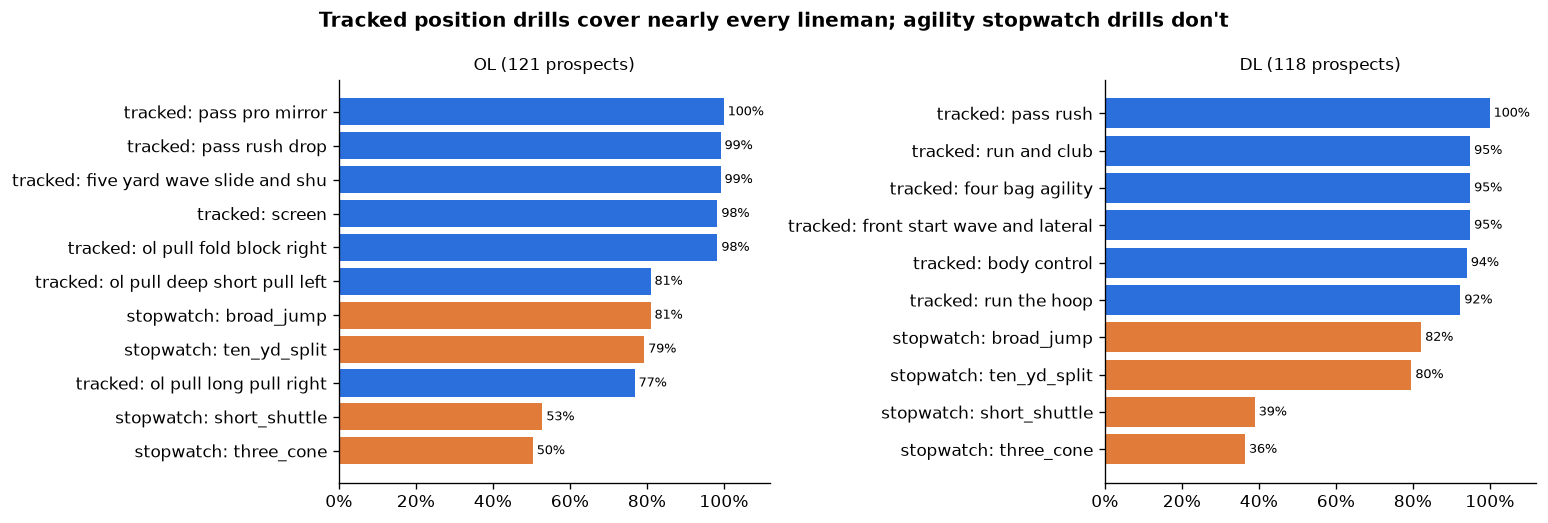

In [8]:
# Fig 1: stopwatch vs tracked-drill coverage by group
rows = []
for g in C.GROUPS:
    n = players.filter(F.col("line_group") == g).count()
    for c in ["three_cone", "short_shuttle", "ten_yd_split", "broad_jump"]:
        rows.append((g, f"stopwatch: {c}", 1 - miss[(g, c)] / 100))
    for d_ in sorted({d for ds in C.TRAIT_DRILLS[g].values() for d in ds} - {"SHORT_SHUTTLE", "THREE_CONE_DRILL", "FORTY_YARD_DASH"}):
        rows.append((g, f"tracked: {d_.lower().replace('_drill', '').replace('_', ' ')[:28]}",
                     ct.filter((F.col("line_group") == g) & (F.col("drill_name") == d_)).select("nfl_id").distinct().count() / n))
cov = pd.DataFrame(rows, columns=["group", "drill", "share"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, g in zip(axes, C.GROUPS):
    d = cov[cov.group == g].sort_values("share")
    ax.barh(d.drill, d.share, color=[ORANGE if s.startswith("stop") else BLUE for s in d.drill])
    for i, v in enumerate(d.share): ax.text(v + .01, i, f"{v:.0%}", va="center", fontsize=8)
    ax.set_xlim(0, 1.12); ax.set_title(f"{g} ({players.filter(F.col('line_group') == g).count()} prospects)", fontsize=10)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Tracked position drills cover nearly every lineman; agility stopwatch drills don't", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_coverage_by_group.png", bbox_inches="tight"); plt.show()

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


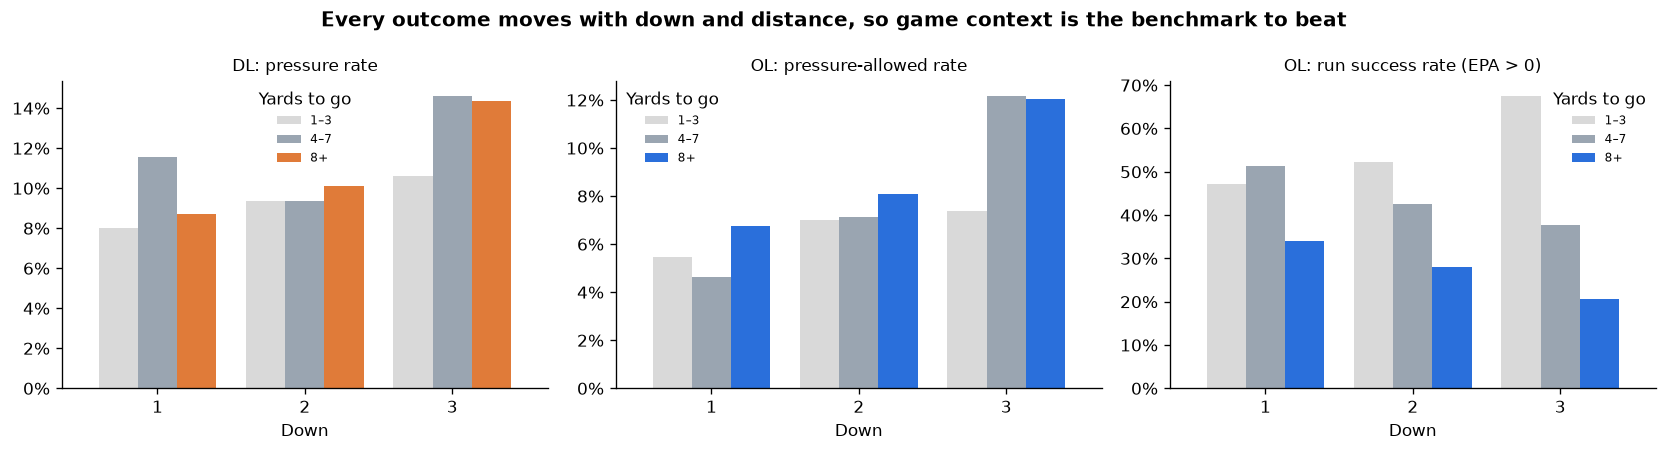

In [9]:
# Fig 2: outcome rates by down and distance for the three outcomes
def by_sit(df, col):
    return (df.filter(F.col("down").between(1, 3)).withColumn("dist", F.when(F.col("yards_to_go") <= 3, "1–3").when(F.col("yards_to_go") <= 7, "4–7").otherwise("8+"))
              .groupBy("down", "dist").agg(F.avg(col).alias("rate")).toPandas().pivot(index="down", columns="dist", values="rate")[["1–3", "4–7", "8+"]])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (df, col, title, c) in zip(axes, [(pr, "pressure", "DL: pressure rate", ORANGE), (pb, "pa", "OL: pressure-allowed rate", BLUE),
                                          (rn, "success", "OL: run success rate (EPA > 0)", BLUE)]):
    by_sit(df, col).plot.bar(ax=ax, rot=0, color=["#d9d9d9", "#9aa5b1", c], width=.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("Down"); ax.legend(title="Yards to go", fontsize=7, frameon=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Every outcome moves with down and distance, so game context is the benchmark to beat", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_outcomes_by_situation.png", bbox_inches="tight"); plt.show()

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


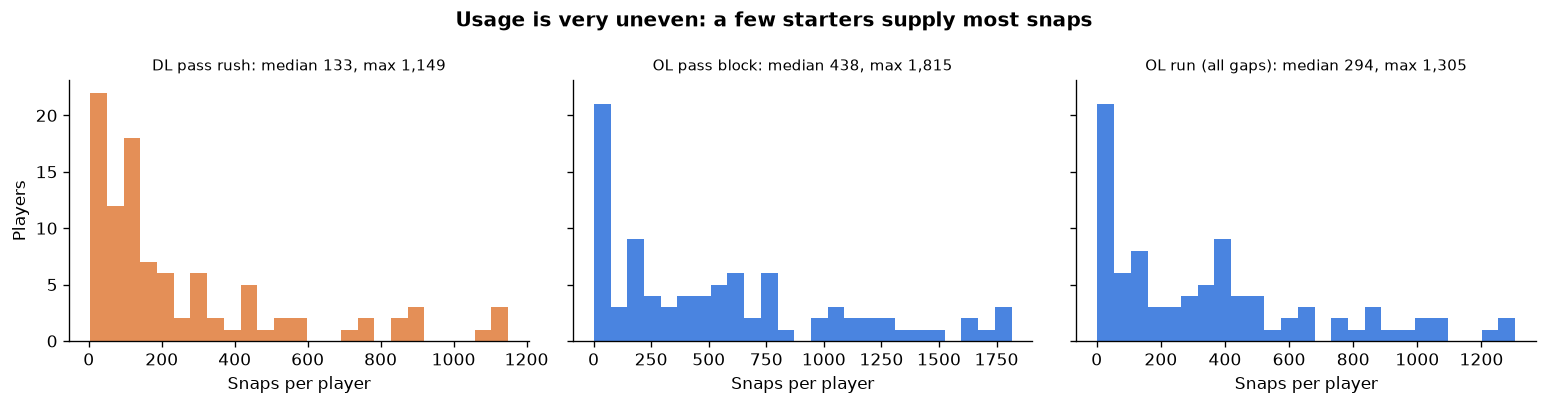

In [10]:
# Fig 3: snaps per player by outcome
spp = {"DL pass rush": pr, "OL pass block": pb, "OL run (all gaps)": rn}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (lab, df) in zip(axes, spp.items()):
    s = df.groupBy("nfl_id").count().toPandas()["count"]
    ax.hist(s, bins=25, color=ORANGE if lab.startswith("DL") else BLUE, alpha=.85)
    ax.set_title(f"{lab}: median {s.median():.0f}, max {s.max():,}", fontsize=9); ax.set_xlabel("Snaps per player")
axes[0].set_ylabel("Players")
fig.suptitle("Usage is very uneven: a few starters supply most snaps", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_snaps_per_player.png", bbox_inches="tight"); plt.show()

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


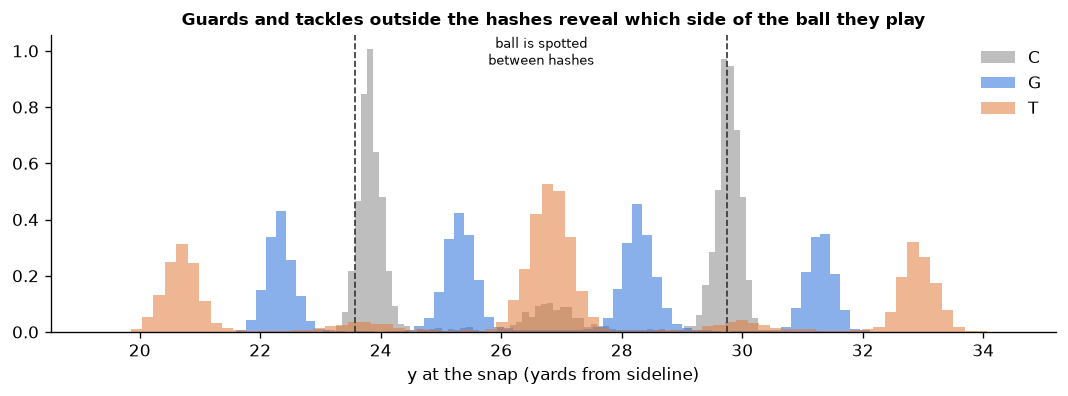

In [11]:
# Fig 4: where guards and tackles line up at the snap, relative to the hash marks (basis of the side inference)
snap_y = (gt.filter(F.col("event") == "ball_snap").select("game_id", "play_id", "nfl_id", "y")
            .join(ol.filter(F.col("lined_up_position").isin("T", "G", "C")).select("game_id", "play_id", "nfl_id", "lined_up_position"),
                  ["game_id", "play_id", "nfl_id"]).sample(fraction=0.3, seed=C.SEED).toPandas())
fig, ax = plt.subplots(figsize=(9, 3.4))
for pos, col in [("C", GREY), ("G", BLUE), ("T", ORANGE)]:
    ax.hist(snap_y[snap_y.lined_up_position == pos].y, bins=80, alpha=.55, color=col, label=pos, density=True)
for h in (C.HASH_LO, C.HASH_HI):
    ax.axvline(h, color="#333", ls="--", lw=1)
ax.text((C.HASH_LO + C.HASH_HI) / 2, ax.get_ylim()[1] * .9, "ball is spotted\nbetween hashes", ha="center", fontsize=8)
ax.set_xlabel("y at the snap (yards from sideline)"); ax.legend(frameon=False)
ax.set_title("Guards and tackles outside the hashes reveal which side of the ball they play", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_ol_position_vs_hashes.png", bbox_inches="tight"); plt.show()

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


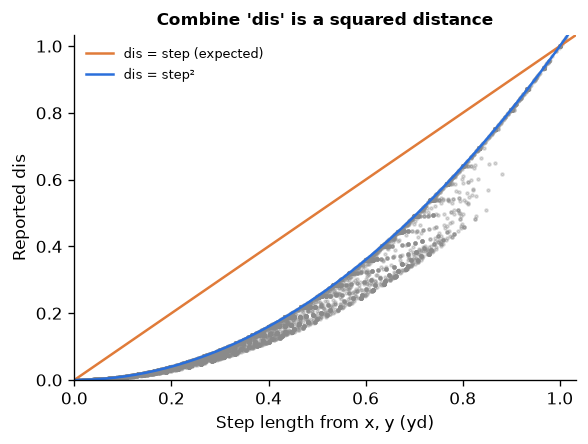

In [12]:
# Fig 5: the 'dis' data-quality problem
smp = ct.filter(F.col("step_xy").isNotNull()).sample(fraction=0.05, seed=C.SEED).select("dis", "step_xy").toPandas()
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.scatter(smp.step_xy, smp.dis, s=3, alpha=.3, color=GREY); lim = smp.step_xy.quantile(.995); xs = np.linspace(0, lim, 50)
ax.plot(xs, xs, color=ORANGE, lw=1.5, label="dis = step (expected)"); ax.plot(xs, xs ** 2, color=BLUE, lw=1.5, label="dis = step²")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel("Step length from x, y (yd)"); ax.set_ylabel("Reported dis"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Combine 'dis' is a squared distance", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_dis_quality_check.png", bbox_inches="tight"); plt.show()

## 6. Whole-release view (team EDA by Isaac Marr)
Sections 1–5 describe the 239 linemen. Isaac's exploration first looked at the **whole release** and then narrowed to the linemen; it is reproduced here from the raw CSVs (explicit schemas, as in his `Data_Loading` notebook), so the report can describe the full data before the cohort filter.
### 6a. Size of the release by season and season type

In [13]:
games_raw = spark.read.csv(C.raw("games.csv"), header=True, nullValue="NA",
                           schema="game_id LONG, game_key INT, season INT, season_type STRING, week INT, home_team_abbr STRING, visitor_team_abbr STRING")
gt_raw = spark.read.csv(C.game_tracking_files(), header=True, nullValue="NA",
                        schema="game_id LONG, play_id INT, nfl_id INT, time STRING, x DOUBLE, y DOUBLE, s DOUBLE, a DOUBLE, dis DOUBLE, o DOUBLE, dir DOUBLE, event STRING")
# player_play: read every column as text (no inferSchema pass) and cast only what is needed
pp_raw = (spark.read.option("header", True).option("nullValue", "NA").option("multiLine", True).option("escape", '"')
          .csv(C.raw("player_play.csv"))
          .select(F.col("game_id").cast("long"), F.col("play_id").cast("int"), F.col("nfl_id").cast("int"),
                  "lined_up_position", F.col("pressure_allowed"), F.col("player_get_off").cast("double")))
g = F.broadcast(games_raw.select("game_id", "season", "season_type"))
frames = gt_raw.join(g, "game_id").groupBy("season", "season_type").agg(F.count("*").alias("tracking_frames"))
pprows = pp_raw.join(g, "game_id").groupBy("season", "season_type").agg(F.count("*").alias("player_play_rows"))
release = (frames.join(pprows, ["season", "season_type"], "outer").orderBy("season", "season_type").toPandas())
release.to_csv(C.TABLE_DIR / "02_release_size.csv", index=False)
tot = release[["tracking_frames", "player_play_rows"]].sum()
regpost = release[release.season_type.isin(["REG", "POST"])][["tracking_frames", "player_play_rows"]].sum()
print(f"all games: {tot.tracking_frames:,.0f} tracking frames, {tot.player_play_rows:,.0f} player-play rows")
print(f"regular + post season: {regpost.tracking_frames:,.0f} frames, {regpost.player_play_rows:,.0f} player-play rows")
release

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


all games: 22,654,290 tracking frames, 314,197 player-play rows
regular + post season: 19,055,148 frames, 262,438 player-play rows


,season,season_type,tracking_frames,player_play_rows
0,2023,POST,114085,1560
1,2023,PRE,728894,10407
2,2023,REG,2822464,38788
3,2024,POST,309862,4351
4,2024,PRE,1292587,18611
5,2024,REG,6225495,85562
6,2025,POST,523090,7258
7,2025,PRE,1577661,22741
8,2025,REG,9060152,124919


### 6b. Combine tracking: what was tracked, for whom
The Combine file also tracks the **ball** (only in the WR / TE route drills, so it cannot time a lineman's reaction to the snap). Players are grouped by the drill family they ran.

In [14]:
ct_raw = spark.read.csv(C.raw("combine_tracking.csv"), header=True, nullValue="NA",
                        schema="draft_year INT, event_id STRING, nfl_id INT, entity_type STRING, time STRING, drill_type STRING, "
                               "drill_name STRING, attempt INT, x DOUBLE, y DOUBLE, s DOUBLE, a DOUBLE, dis DOUBLE, dir DOUBLE")
cpos = spark.read.csv(C.raw("combine_results.csv"), header=True, nullValue="NA",
                      schema="draft_year INT, nfl_id INT, combine_position STRING").select("nfl_id", "combine_position")
print("frames by entity type:", {r.entity_type: r["count"] for r in ct_raw.groupBy("entity_type").count().collect()})
print("drill attempts (events):", ct_raw.select("event_id").distinct().count(),
      "| tracked players:", ct_raw.filter(F.col("entity_type") == "PLAYER").select("nfl_id").distinct().count())
ctp = ct_raw.filter(F.col("entity_type") == "PLAYER")
coverage = (ctp.join(cpos, "nfl_id").groupBy("drill_type").pivot("combine_position").agg(F.countDistinct("nfl_id"))
               .join(ctp.groupBy("drill_type").agg(F.count("*").alias("frames"), F.countDistinct("nfl_id").alias("players"),
                                                    F.countDistinct("event_id").alias("attempts")), "drill_type")
               .orderBy(F.desc("players")).toPandas().fillna(0))
coverage.to_csv(C.TABLE_DIR / "02_drill_coverage.csv", index=False)
coverage

frames by entity type: {'PLAYER': 431094, 'BALL': 32095}


drill attempts (events): 6310 | tracked players: 510


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,drill_type,DB,DL,OL,TE,WR,frames,players,attempts
0,FORTY_YARD_DASH,102.0,93.0,95.0,34.0,94.0,41500,418,793
1,SHORT_SHUTTLE,28.0,38.0,54.0,21.0,29.0,11690,170,223
2,THREE_CONE_DRILL,24.0,45.0,48.0,19.0,24.0,15951,160,203
3,SKILL_DRILLS_DB,122.0,0.0,0.0,0.0,0.0,94623,122,1170
4,SKILL_DRILLS_OL,0.0,0.0,121.0,0.0,0.0,61129,121,910
5,SKILL_DRILLS_DL,0.0,114.0,0.0,0.0,0.0,77428,114,1007
6,SKILL_DRILLS_WR,0.0,0.0,0.0,0.0,107.0,96408,107,1529
7,SKILL_DRILLS_TE,0.0,0.0,0.0,42.0,0.0,29102,42,438
8,SKILL_DRILLS_LB,0.0,4.0,0.0,0.0,0.0,3263,4,37


In [15]:
# the lineman drills, by name: players and attempts (PASS_PRO-MIRROR vs PASS_PRO_MIRROR is the naming inconsistency of section 4)
lineman_drills = (ctp.filter(F.col("drill_type").isin("SKILL_DRILLS_OL", "SKILL_DRILLS_DL"))
                     .groupBy("drill_type", "drill_name").agg(F.countDistinct("nfl_id").alias("players"),
                                                             F.countDistinct("event_id").alias("attempts"))
                     .orderBy("drill_type", F.desc("players")).toPandas())
lineman_drills.to_csv(C.TABLE_DIR / "02_lineman_drills.csv", index=False)
lineman_drills

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,drill_type,drill_name,players,attempts
0,SKILL_DRILLS_DL,PASS_RUSH_DRILL,114,217
1,SKILL_DRILLS_DL,RUN_AND_CLUB_DRILL,112,113
2,SKILL_DRILLS_DL,FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION,112,112
3,SKILL_DRILLS_DL,FOUR_BAG_AGILITY_DRILL,112,112
4,SKILL_DRILLS_DL,BODY_CONTROL_DRILL,111,113
5,SKILL_DRILLS_DL,RUN_THE_HOOP_DRILL,109,119
6,SKILL_DRILLS_DL,BACK_PEDAL_AND_REACT,55,58
7,SKILL_DRILLS_DL,SHORT_ZONE_BREAKS,36,105
8,SKILL_DRILLS_DL,SHORT_ZONE_BREAK_FORWARD,20,20
9,SKILL_DRILLS_DL,SHORT_ZONE_BREAK_FLAT_WHEEL,20,20


### 6c. How many players have enough NFL snaps?
Regular + post season. Pass-block snaps = rows with a `pressure_allowed` value; rush snaps = rows with a `player_get_off` value. The thresholds show how many players a player-level analysis can use.

In [16]:
rp = pp_raw.join(g.filter(F.col("season_type").isin("REG", "POST")), "game_id")
per_player = (cpos.join(rp, "nfl_id", "left").groupBy("nfl_id", "combine_position")
                  .agg(F.count("play_id").alias("snaps"), F.count("pressure_allowed").alias("ol_pass_block_snaps"),
                       F.count("player_get_off").alias("dl_rush_snaps")))
snaps_by_pos = (C.describe(per_player, ["snaps", "ol_pass_block_snaps", "dl_rush_snaps"], by=["combine_position"])
                  .orderBy("column", "combine_position").toPandas().round(0))
snaps_by_pos.to_csv(C.TABLE_DIR / "02_snaps_by_position.csv", index=False)
v = F.when(F.col("combine_position") == "OL", F.col("ol_pass_block_snaps")).otherwise(F.col("dl_rush_snaps"))
thresholds = (per_player.filter(F.col("combine_position").isin("OL", "DL"))
                 .groupBy(F.col("combine_position").alias("group"))
                 .agg(F.count(F.lit(1)).alias("players"), F.sum((v == 0).cast("int")).alias("0 snaps"),
                      *[F.sum((v >= k).cast("int")).alias(f"{k}+") for k in (50, 100, 200)])
                 .withColumn("snap type", F.when(F.col("group") == "OL", "pass-block snaps").otherwise("rush snaps"))
                 .orderBy(F.desc("group")).toPandas())
thresholds.to_csv(C.TABLE_DIR / "02_snap_thresholds.csv", index=False)
thresholds

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,group,players,0 snaps,50+,100+,200+,snap type
0,OL,121,32,70,67,60,pass-block snaps
1,DL,118,20,82,70,50,rush snaps


### 6d. DL get-off by alignment, and a first look at the 10-yard split
Get-off = time for a rusher to cross the line after the snap. Edge rushers and interior linemen have different distributions, so later analyses keep alignment (or the share of edge snaps) as context. Isaac's first scatter, the 10-yard split against a player's average get-off, is the starting point of the player-level analysis in notebook 07b.

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


                           column  count   mean    std    min  median    max  missing_pct
lined_up_position                                                                        
INTERIOR_LINE      player_get_off  13637  1.083  0.284  0.024   1.026  2.000          0.0
EDGE               player_get_off  21417  0.966  0.289  0.004   0.907  1.998          0.0


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


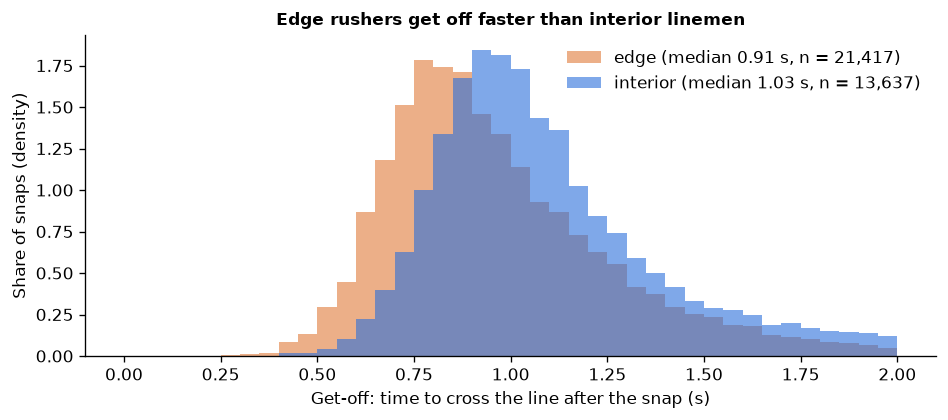

In [17]:
dl_ids = cpos.filter(F.col("combine_position") == "DL").select("nfl_id")
dl_go = (rp.join(dl_ids, "nfl_id").filter(F.col("player_get_off").isNotNull() & F.col("lined_up_position").isin("EDGE", "INTERIOR_LINE"))
           .select("nfl_id", "player_get_off", "lined_up_position"))
go_desc = C.describe(dl_go, ["player_get_off"], by=["lined_up_position"]).toPandas().set_index("lined_up_position")
print(go_desc.round(3))
bins = np.linspace(0, 2, 41)
hist = C.histogram(dl_go, "player_get_off", bins, by=["lined_up_position"]).toPandas()    # bin counts from Spark
fig, ax = plt.subplots(figsize=(8, 3.6))
for pos, col, lab in [("EDGE", ORANGE, "edge"), ("INTERIOR_LINE", BLUE, "interior")]:
    h = hist[hist.lined_up_position == pos]; n = go_desc.loc[pos, "count"]
    ax.bar(h.left, h["count"] / (n * (bins[1] - bins[0])), width=bins[1] - bins[0], align="edge", alpha=.6, color=col,
           label=f"{lab} (median {go_desc.loc[pos, 'median']:.2f} s, n = {int(n):,})")
ax.set_xlabel("Get-off: time to cross the line after the snap (s)"); ax.set_ylabel("Share of snaps (density)"); ax.legend(frameon=False)
ax.set_title("Edge rushers get off faster than interior linemen", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_dl_getoff_by_alignment.png", bbox_inches="tight"); plt.show()

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


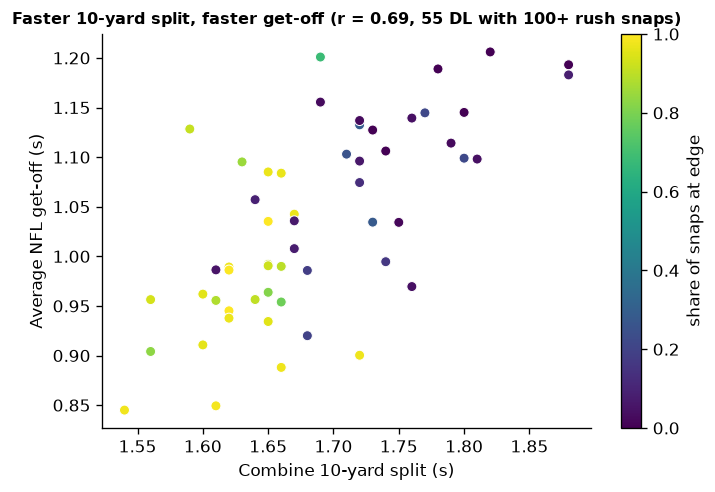

In [18]:
stop = spark.read.csv(C.raw("combine_results.csv"), header=True, nullValue="NA",
                      schema="draft_year INT, nfl_id INT, combine_position STRING, combine_height DOUBLE, combine_weight DOUBLE, "
                             "hand_size DOUBLE, arm_length DOUBLE, wing_span DOUBLE, ten_yd_split DOUBLE").select("nfl_id", "ten_yd_split")
first_look = (dl_go.groupBy("nfl_id").agg(F.count("*").alias("rush_snaps"), F.avg("player_get_off").alias("mean_get_off"),
                                         F.avg((F.col("lined_up_position") == "EDGE").cast("double")).alias("edge_share"))
                   .filter(F.col("rush_snaps") >= 100).join(stop, "nfl_id").dropna(subset=["ten_yd_split"]))
r = C.pearson(first_look, "ten_yd_split", "mean_get_off").first()["pearson_r"]          # Spark
first_look = first_look.toPandas()                                                      # 55 points, for the scatter only
fig, ax = plt.subplots(figsize=(6, 4.2))
sc = ax.scatter(first_look.ten_yd_split, first_look.mean_get_off, c=first_look.edge_share, cmap="viridis", vmin=0, vmax=1, s=36,
                edgecolors="white", linewidths=.6)
fig.colorbar(sc, ax=ax, label="share of snaps at edge")
ax.set_xlabel("Combine 10-yard split (s)"); ax.set_ylabel("Average NFL get-off (s)")
ax.set_title(f"Faster 10-yard split, faster get-off (r = {r:.2f}, {len(first_look)} DL with 100+ rush snaps)", fontweight="bold", fontsize=9.5)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_ten_yd_split_vs_getoff.png", bbox_inches="tight"); plt.show()